File Check

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_PATH = Path("../data/raw/paysim.csv")

print("File exists:", DATA_PATH.exists())
print("File size (MB):", round(DATA_PATH.stat().st_size / 1024**2, 1))

File exists: True
File size (MB): 470.7


In [3]:
peek = pd.read_csv(DATA_PATH, nrows=5)
peek

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [4]:
dtypes = {
    "step": "uint16",
    "type": "category",
    "amount": "float64",
    "oldbalanceOrg": "float64",
    "newbalanceOrig": "float64",
    "oldbalanceDest": "float64",
    "newbalanceDest": "float64",
    "isFraud": "int8",
    "isFlaggedFraud": "int8",
}

df = pd.read_csv(DATA_PATH, usecols=list(dtypes), dtype=dtypes)

In [5]:
print("Shape (rows, columns):", df.shape)
df.info(memory_usage="deep")

Shape (rows, columns): (6362620, 9)
<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 9 columns):
 #   Column          Dtype   
---  ------          -----   
 0   step            uint16  
 1   type            category
 2   amount          float64 
 3   oldbalanceOrg   float64 
 4   newbalanceOrig  float64 
 5   oldbalanceDest  float64 
 6   newbalanceDest  float64 
 7   isFraud         int8    
 8   isFlaggedFraud  int8    
dtypes: category(1), float64(5), int8(2), uint16(1)
memory usage: 273.1 MB


In [6]:
df.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,0,0
1,1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,0,0
2,1,TRANSFER,181.00,181.0,0.00,0.0,0.0,1,0
3,1,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,0,0


In [7]:
df.tail()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
6362615,743,CASH_OUT,339682.13,339682.13,0.0,0.00,339682.13,1,0
6362616,743,TRANSFER,6311409.28,6311409.28,0.0,0.00,0.00,1,0
6362617,743,CASH_OUT,6311409.28,6311409.28,0.0,68488.84,6379898.11,1,0
6362618,743,TRANSFER,850002.52,850002.52,0.0,0.00,0.00,1,0
6362619,743,CASH_OUT,850002.52,850002.52,0.0,6510099.11,7360101.63,1,0


In [8]:
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 20

balance_cols = ["oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]

In [9]:
missing = df.isnull().sum()
print("Missing values per column:")
print(missing)
print("\nTotal missing values:", missing.sum())

dup_count = df.duplicated().sum()
print("\nExact duplicate rows:", dup_count)

Missing values per column:
step              0
type              0
amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Total missing values: 0

Exact duplicate rows: 543


In [10]:
print("Rows with amount <= 0:", (df["amount"] <= 0).sum())
print("Rows with any negative balance:", (df[balance_cols] < 0).any(axis=1).sum())
print("step range:", df["step"].min(), "to", df["step"].max())
print("Distinct step values:", df["step"].nunique())

Rows with amount <= 0: 16
Rows with any negative balance: 0
step range: 1 to 743
Distinct step values: 743


In [11]:
df[["step", "amount"] + balance_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
step,"6,362,620.00",243.40,142.33,1.00,156.00,239.00,335.00,743.00
amount,"6,362,620.00","179,861.90","603,858.23",0.00,"13,389.57","74,871.94","208,721.48","92,445,516.64"
oldbalanceOrg,"6,362,620.00","833,883.10","2,888,242.67",0.00,0.00,"14,208.00","107,315.18","59,585,040.37"
newbalanceOrig,"6,362,620.00","855,113.67","2,924,048.50",0.00,0.00,0.00,"144,258.41","49,585,040.37"
oldbalanceDest,"6,362,620.00","1,100,701.67","3,399,180.11",0.00,0.00,"132,705.66","943,036.71","356,015,889.35"
newbalanceDest,"6,362,620.00","1,224,996.40","3,674,128.94",0.00,0.00,"214,661.44","1,111,909.25","356,179,278.92"


In [12]:
counts = df["isFraud"].value_counts().sort_index()
percent = (counts / len(df) * 100).round(4)

summary = pd.DataFrame({"count": counts, "percent": percent})
summary.index = ["Genuine (0)", "Fraud (1)"]
print(summary)

ratio = counts.loc[0] / counts.loc[1]
print(f"\nImbalance ratio: about {ratio:,.0f} genuine transactions per 1 fraud")

               count  percent
Genuine (0)  6354407    99.87
Fraud (1)       8213     0.13

Imbalance ratio: about 774 genuine transactions per 1 fraud


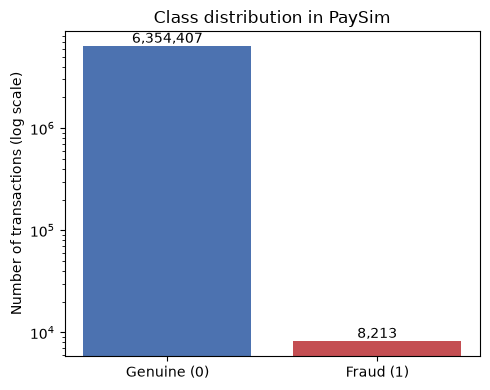

In [13]:
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Genuine (0)", "Fraud (1)"], counts.values, color=["#4C72B0", "#C44E52"])
ax.set_yscale("log")
ax.set_ylabel("Number of transactions (log scale)")
ax.set_title("Class distribution in PaySim")

for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")

plt.tight_layout()
plt.savefig("../reports/figures/01_class_distribution.png", dpi=150)
plt.show()

In [14]:
type_summary = pd.DataFrame({
    "count": df["type"].value_counts(),
    "percent": (df["type"].value_counts(normalize=True) * 100).round(2)
})
type_summary

,count,percent
type,,
CASH_OUT,2237500,35.17
PAYMENT,2151495,33.81
CASH_IN,1399284,21.99
TRANSFER,532909,8.38
DEBIT,41432,0.65


Skewness of amount: 30.99


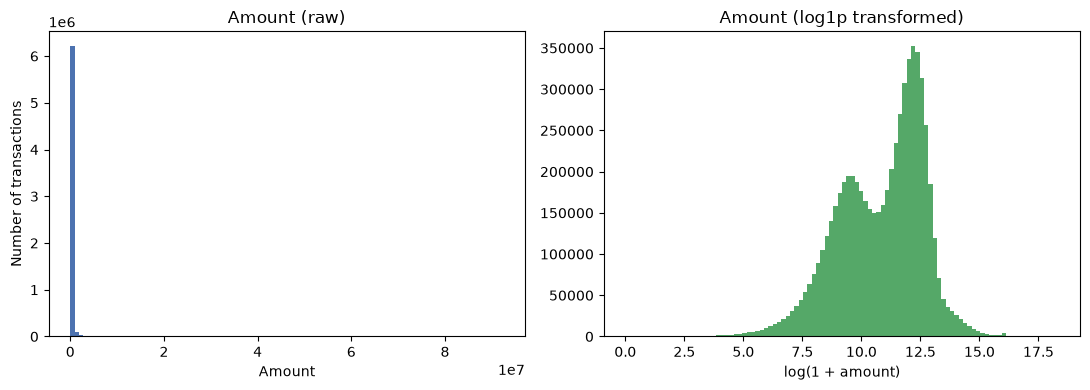

In [15]:
print("Skewness of amount:", round(df["amount"].skew(), 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df["amount"], bins=100, color="#4C72B0")
axes[0].set_title("Amount (raw)")
axes[0].set_xlabel("Amount")
axes[0].set_ylabel("Number of transactions")

axes[1].hist(np.log1p(df["amount"]), bins=100, color="#55A868")
axes[1].set_title("Amount (log1p transformed)")
axes[1].set_xlabel("log(1 + amount)")

plt.tight_layout()
plt.savefig("../reports/figures/02_amount_distribution.png", dpi=150)
plt.show()

In [16]:
extras = df.duplicated()
print("Extra copies (what removal would delete):", extras.sum())
print("  of which fraud:", df.loc[extras, "isFraud"].sum())

group_mask = df.duplicated(keep=False)
dups = df[group_mask]
print("\nAll rows that belong to a duplicate group:", len(dups))

print("\nBy fraud label:")
print(dups["isFraud"].value_counts())

print("\nBy transaction type:")
print(dups["type"].value_counts())

print("\nDuplicate rows with amount = 0:", (dups["amount"] == 0).sum())

dups.sort_values(["step", "type", "amount"]).head(10)

Extra copies (what removal would delete): 543
  of which fraud: 16

All rows that belong to a duplicate group: 1081

By fraud label:
isFraud
0    1054
1      27
Name: count, dtype: int64

By transaction type:
type
PAYMENT     1054
CASH_OUT      27
CASH_IN        0
DEBIT          0
TRANSFER       0
Name: count, dtype: int64

Duplicate rows with amount = 0: 2


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
10884,7,PAYMENT,"1,849.50",0.00,0.00,0.00,0.00,0,0
11104,7,PAYMENT,"1,849.50",0.00,0.00,0.00,0.00,0,0
27043,8,PAYMENT,"7,759.31",0.00,0.00,0.00,0.00,0,0
33556,8,PAYMENT,"7,759.31",0.00,0.00,0.00,0.00,0,0
51253,9,PAYMENT,"2,388.93",0.00,0.00,0.00,0.00,0,0
59969,9,PAYMENT,"2,388.93",0.00,0.00,0.00,0.00,0,0
48847,9,PAYMENT,"2,783.83",0.00,0.00,0.00,0.00,0,0
63096,9,PAYMENT,"2,783.83",0.00,0.00,0.00,0.00,0,0
56420,9,PAYMENT,"6,499.28",0.00,0.00,0.00,0.00,0,0
72575,9,PAYMENT,"6,499.28",0.00,0.00,0.00,0.00,0,0


In [17]:
zero_amt = df[df["amount"] == 0]
print("Zero-amount rows:", len(zero_amt))
print("\nBy fraud label:")
print(zero_amt["isFraud"].value_counts())
print("\nBy type (zero counts are just empty categories):")
print(zero_amt["type"].value_counts())
zero_amt

Zero-amount rows: 16

By fraud label:
isFraud
1    16
Name: count, dtype: int64

By type (zero counts are just empty categories):
type
CASH_OUT    16
CASH_IN      0
DEBIT        0
PAYMENT      0
TRANSFER     0
Name: count, dtype: int64


,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
2736447,212,CASH_OUT,0.00,0.00,0.00,0.00,0.00,1,0
3247298,250,CASH_OUT,0.00,0.00,0.00,0.00,0.00,1,0
3760289,279,CASH_OUT,0.00,0.00,0.00,"538,547.63","538,547.63",1,0
5563714,387,CASH_OUT,0.00,0.00,0.00,"7,970,766.57","7,970,766.57",1,0
5996408,425,CASH_OUT,0.00,0.00,0.00,"76,759.90","76,759.90",1,0
5996410,425,CASH_OUT,0.00,0.00,0.00,"2,921,531.34","2,921,531.34",1,0
6168500,554,CASH_OUT,0.00,0.00,0.00,"230,289.66","230,289.66",1,0
6205440,586,CASH_OUT,0.00,0.00,0.00,"1,328,472.86","1,328,472.86",1,0
6266414,617,CASH_OUT,0.00,0.00,0.00,0.00,0.00,1,0
6281483,646,CASH_OUT,0.00,0.00,0.00,0.00,0.00,1,0


## Decisions so far (Phase 2, Part B)
- No missing values, so no imputation is needed.
- No negative amounts or balances.
- 543 exact duplicate rows (16 are fraud): KEPT. nameOrig/nameDest were not loaded, so they cannot be proven to be errors, and removal would shrink the fraud class.
- 16 zero-amount rows (all CASH_OUT, all fraud): KEPT. Simulator quirk, to be noted in limitations.
- No outlier clipping: very large amounts may be exactly where fraud lives.
- Fraud rate 0.13% (8,213 of 6,362,620), about 774 genuine per fraud.
- amount is heavily skewed, so a log transform is planned for Phase 3.